In [53]:
from pathlib import Path
import matplotlib.pyplot as plt
import json
import pandas as pd
import numpy as np
import lightkurve as lk
import warnings
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

### 1. Extracting Ground Truth from the data

In [27]:
# Load the CSV file into a Pandas dataframe
df = pd.read_csv('zooniverse_mock_data.csv')
df

,classification_id,user_name,annotations,subject_data
0,1001,AstroFan22,"[{""task"": ""T0"", ""value"": ""Yes""}]","{""9991"": {""TIC ID"": ""261136679"", ""Sector"": ""1""}}"
1,1002,SpaceNerd,"[{""task"": ""T0"", ""value"": ""Yes""}]","{""9991"": {""TIC ID"": ""261136679"", ""Sector"": ""1""}}"
2,1003,StarGazer,"[{""task"": ""T0"", ""value"": ""No""}]","{""9991"": {""TIC ID"": ""261136679"", ""Sector"": ""1""}}"
3,1004,AstroFan22,"[{""task"": ""T0"", ""value"": ""No""}]","{""9992"": {""TIC ID"": ""112233445"", ""Sector"": ""1""}}"
4,1005,NovaHunter,"[{""task"": ""T0"", ""value"": ""No""}]","{""9992"": {""TIC ID"": ""112233445"", ""Sector"": ""1""}}"


Zooniverse.org exports data in a unique JSON format, for example {"9991": {"TIC ID": "261136679"}}

From this metadata, the TIC ID of the target and the votes ("Yes"/"No") stored in 'value' are required. Build functions to extract TIC ID and vote-

In [28]:
def extract_TIC_ID(subject_json_str):
    data = json.loads(subject_json_str)

    for random_id, metadata in data.items():
        return metadata.get('TIC ID')


def extract_vote(annotations_json_str):
    data = json.loads(annotations_json_str)

    return data[0].get('value')

In [36]:
# Adding the extracted TIC ID and Vote as well as the vote in binary form ("Yes" = 1, "No" = 0) (This will be required later) to the dataframe
df['TIC_ID'] = df['subject_data'].apply(extract_TIC_ID)
df['Vote'] = df['annotations'].apply(extract_vote)

# Using Vectorization to convert string votes to binary votes
df['Vote_b'] = (df['Vote'] == "Yes").astype(int)
df

,classification_id,user_name,annotations,subject_data,TIC_ID,Vote,Vote_b
0,1001,AstroFan22,"[{""task"": ""T0"", ""value"": ""Yes""}]","{""9991"": {""TIC ID"": ""261136679"", ""Sector"": ""1""}}",261136679,Yes,1
1,1002,SpaceNerd,"[{""task"": ""T0"", ""value"": ""Yes""}]","{""9991"": {""TIC ID"": ""261136679"", ""Sector"": ""1""}}",261136679,Yes,1
2,1003,StarGazer,"[{""task"": ""T0"", ""value"": ""No""}]","{""9991"": {""TIC ID"": ""261136679"", ""Sector"": ""1""}}",261136679,No,0
3,1004,AstroFan22,"[{""task"": ""T0"", ""value"": ""No""}]","{""9992"": {""TIC ID"": ""112233445"", ""Sector"": ""1""}}",112233445,No,0
4,1005,NovaHunter,"[{""task"": ""T0"", ""value"": ""No""}]","{""9992"": {""TIC ID"": ""112233445"", ""Sector"": ""1""}}",112233445,No,0


Ground truth values are not a given, specially when performing observations for a new star. The ground truth are values are determined by calculating the consensus using user votes from Zooniverse.org

For each star (grouped by TIC_ID's), the mean of the binary votes is taken. If the mean is greater than 0.5 (arbitrary value, can set it higher if higher confidence is required), then the ground truth is set to 1, else it is set to 0.


In [43]:
consensus = df.groupby('TIC_ID')['Vote_b'].mean().reset_index()

consensus['final_label'] = (consensus['Vote_b'] >= 0.5).astype(int)
consensus

,TIC_ID,Vote_b,final_label
0,112233445,0.000000,0
1,261136679,0.666667,1


### 2. Prepare Data Directories
These will be used by the custom DataLoader to load lightcurve data

In [45]:
# Creating directories for data and lightcurves separately for a clean path
data_path = Path("data")
lightcurves_path = data_path / "lightcurves"

# parents = True creates 'data' and 'data/lightcurves' both
lightcurves_path.mkdir(parents = True, exist_ok = True)

# Save processed labels to the data directory
labels_path = data_path / "processed_labels.csv"
consensus.to_csv(labels_path, index = False)
print(f"Saved processed labels to {labels_path} successfully")

Saved processed labels to data/processed_labels.csv successfully


### 3. Transform and Load Data

In [52]:
# Setting up target tensor length before hand to prevent shape mismatch errors in the future
target_length = 20000
successful_stars = 0

# Setting up a loop to iterate over all the stars in the consensus list
for index, row in tqdm(consensus.iterrows(), total = len(consensus), desc = "Processing Stars"):
    tic_id = row['TIC_ID']
    label = row['final_label']

    # If the star data proccesses successfully, it will be saved on this file path
    save_path = lightcurves_path / f"TIC_{tic_id}.npy"

    # Recovery method - saving data downloaded until now to the drive and skipping already downloaded data in the event of a crash (also saves a lot of time in re-downloading the data)
    if save_path.is_file():
        successful_stars += 1
        continue

    try:
        # Download the raw data
        search_result = lk.search_lightcurve(f"TIC {tic_id}", mission = "TESS", author = "SPOC", sector = 1)
        if len(search_result) == 0:
            tqdm.write(f"TIC {tic_id} download failed.")
            continue

        lc = search_result[0].download()

        # Transform data
        lc_cleaned = lc.remove_nans().flatten(window_length = 901)

        # Find orbital period using BLS
        periodogram = lc_cleaned.to_periodogram(method = "bls", minimum_period = 1, maximum_period = 15)
        best_period = periodogram.period_at_max_power
        first_epoch = periodogram.transit_time_at_max_power

        # Phase-fold the data based on calculated orbital period
        lc_folded = lc_cleaned.fold(period = best_period, epoch_time = first_epoch)

        # Extracting raw number and shaping tensor data
        raw_flux = lc_folded.flux.value
        
        # Remove the Astropy 'MaskedNDArray' wrap if it exists
        if hasattr(raw_flux, 'unmasked'):
            flux_array = raw_flux.unmasked
        else:
            flux_array = raw_flux
            
        # Convert the datatype into float32, will be useful later on while using PyTorch
        flux_array = np.array(flux_array, dtype = np.float32)
        
        if len(flux_array) > target_length:
            flux_array = flux_array[:target_length] # Removes excess data points
        else:
            padding = np.ones(target_length - len(flux_array), dtype = np.float32)
            flux_array = np.concatenate((flux_array, padding)) # Adds extra data points with flux = 1.0 (normalized stellar brightness)
        
        # Save data (NumPy array) as a binary file (.npy)
        np.save(save_path, flux_array)
        successful_stars += 1

    except Exception as e:
        tqdm.write(f"TIC {tic_id} failed during processing: {e}")

print(f"Successfully processed and saved {successful_stars}/{len(consensus)} stars.")
    

Processing Stars:   0%|          | 0/2 [00:00<?, ?it/s]

TIC 112233445 download failed.
Successfully processed and saved 1/2 stars.


### 4. Verifying the generated .npy file and plot the results

(20000,)


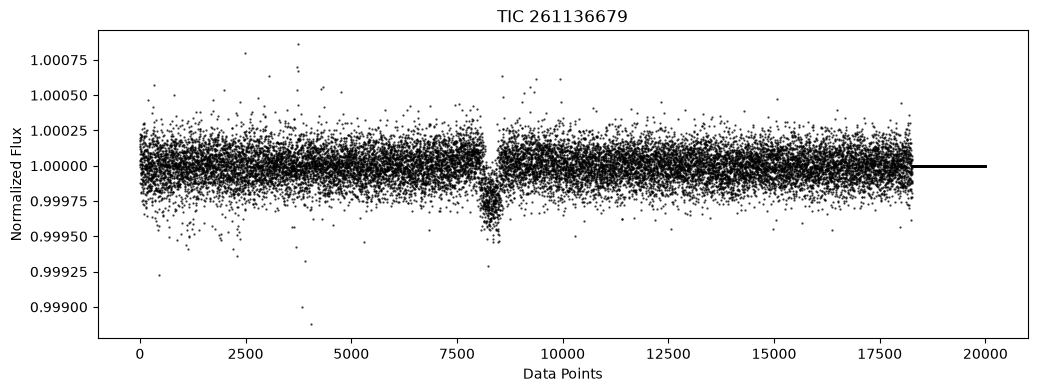

In [61]:
# Load the binary file back into NumPy array
file_path = "data/lightcurves/TIC_261136679.npy"
loaded_flux = np.load(file_path)

# Check the shape
print(loaded_flux.shape)

# Plot the results
plt.figure(figsize = (12, 4))
plt.plot(loaded_flux, linewidth = 0, marker = '.', markersize = 1.3, color = 'black', alpha = 0.7)
plt.title("TIC 261136679")
plt.xlabel("Data Points")
plt.ylabel("Normalized Flux")
plt.show()